# Central fotovoltaica · Análisis en Python (corte 3)

Procesa las medidas del ESP32 (sensores INA260) y genera gráficas y tablas.
Ejecutar de arriba abajo: **Kernel → Restart & Run All**. Requiere `pandas`, `numpy`, `matplotlib` y `openpyxl`.

| Nodo | Qué mide |
|---|---|
| entrada (`0x40`) | paneles o batería, según la prueba |
| salida (`0x44`) | salida del elevador MT3608 (5 V) hacia la carga |

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display
from fisica import *

SAL = RAIZ / "graficas"; TAB = RAIZ / "tablas"
SAL.mkdir(exist_ok=True); TAB.mkdir(exist_ok=True)
AZUL, NAR, VERDE, ROJO, GRIS, AMAR = "#004883", "#eb6834", "#1f9d55", "#c0392b", "#5b6672", "#e0a800"
plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 1.8})
pd.set_option("display.precision", 3)
RES = {}  # números que usa la presentación
def guardar(fig, nombre):
    fig.tight_layout(); fig.savefig(SAL / nombre, bbox_inches="tight"); plt.show()

## Requerimiento 1 · Procesamiento de datos y modelado físico

### 1.1 Funciones físicas
Definidas en `fisica.py`. Unidades: V, mA, mW, mWh, s, Ω.

| Función | Ecuación |
|---|---|
| `ohm_v`, `ohm_i`, `ohm_r` | V = I · R |
| `potencia` | P = V · I |
| `energia` | E = ∫ P dt (regla del trapecio) |
| `eficiencia` | η = P<sub>sal</sub> / P<sub>ent</sub> · 100 |
| `error_pct` | \|real − teórico\| / \|teórico\| · 100 |

In [2]:
# Prueba rápida de las funciones con valores conocidos.
print("V con 100 mA y 50 Ω   :", ohm_v(100, 50), "V")
print("R con 5 V y 100 mA    :", ohm_r(5.0, 100), "Ω")
print("P con 5 V y 100 mA    :", potencia(5.0, 100), "mW")
print("E de 100 mW por 1 h   :", round(energia(np.arange(0, 3601, 5), np.full(721, 100))[-1], 3), "mWh")
print("η 473 de 547 mW       :", round(eficiencia(473, 547), 1), "%")

V con 100 mA y 50 Ω   : 5.0 V
R con 5 V y 100 mA    : 50.0 Ω
P con 5 V y 100 mA    : 500.0 mW
E de 100 mW por 1 h   : 100.0 mWh
η 473 de 547 mW       : 86.5 %


### 1.2 Importar los datos
Cada Excel que descarga la página del ESP32 trae la hoja `Prueba N`. Se cargan todas en un solo `DataFrame`.
Se usan **todos** los Excel, en tres lotes; la letra evita que se repitan los números de prueba:

| Lote | Fechas | Pruebas |
|---|---|---|
| A | 14–19 oct | A1–A10 · el sensor de entrada pasó al lado de los paneles después de A8 |
| B | 30 oct–4 nov | B1, B3–B6, B19, B20, B22–B24 |
| C | 19–23 nov, 6 paneles | C1–C8 |

Las pruebas de consumo son de noche con la batería: C2 y C4 quedaron como "paneles" en la página y el script las toma como batería.

In [3]:
d = cargar()
print(d.shape[0], "filas ·", d.prueba.nunique(), "pruebas")
pruebas = d.groupby("prueba", sort=False).agg(fuente=("fuente", "first"), nombre=("nombre", "first"), filas=("n", "size"),
                                  inicio=("fecha", "min"), horas=("h", "max"))
display(pruebas)
RES["pruebas"] = {p: [r.fuente, int(r.filas), round(r.horas, 2)] for p, r in pruebas.iterrows()}
d.head()

90245 filas · 28 pruebas


,fuente,nombre,filas,inicio,horas
prueba,,,,,
A1,paneles,,19627,2026-10-14 11:10:54.327,21.740
A2,paneles,Prueba 2 (paneles),807,2026-10-15 08:55:19.329,0.813
A3,paneles,Prueba 3 (panelesl,3725,2026-10-15 09:44:06.066,10.250
A4,bateria,Aguante de batería,3784,2026-10-15 19:59:06.392,1.344
A5,bateria,Cambio de tiempo de muestras,5556,2026-10-15 21:19:47.292,38.512
A6,bateria,,23,2026-10-17 11:50:34.274,0.141
A7,bateria,,146,2026-10-17 11:59:02.282,8.625
A8,bateria,,3295,2026-10-17 20:36:36.287,4.575
A9,carga,,240,2026-10-18 07:42:53.023,0.332


,n,fecha,t,V,I,P_esp,E_esp,Vs,Is,Ps_esp,Es_esp,h,nombre,prueba,fuente
0,1,2026-10-14 11:10:54.327,0.327,0.0,0.0,0.0,0.0,4.946,22.5,111.285,0.000,9.083e-05,,A1,paneles
1,2,2026-10-14 11:10:59.327,5.327,0.0,0.0,0.0,0.0,4.945,22.5,111.263,0.155,1.480e-03,,A1,paneles
2,3,2026-10-14 11:11:04.328,10.328,0.0,0.0,0.0,0.0,4.944,22.5,111.240,0.309,2.869e-03,,A1,paneles
3,4,2026-10-14 11:11:09.328,15.328,0.0,0.0,0.0,0.0,4.948,22.5,111.330,0.464,4.258e-03,,A1,paneles
4,5,2026-10-14 11:11:14.328,20.328,0.0,0.0,0.0,0.0,4.946,22.5,111.285,0.618,5.647e-03,,A1,paneles


### 1.3 Calcular potencia y energía con el script
El ESP32 ya entrega P y E. Aquí se recalculan desde V e I para comprobarlos.
El ESP32 suma la energía por rectángulos; aquí se usa la regla del trapecio.

In [4]:
d["P"] = potencia(d.V, d.I); d["Ps"] = potencia(d.Vs, d.Is)
d["E"] = d.groupby("prueba", group_keys=False).apply(lambda g: pd.Series(energia(g.t, g.P), g.index))
d["Es"] = d.groupby("prueba", group_keys=False).apply(lambda g: pd.Series(energia(g.t, g.Ps), g.index))
d["R_carga"] = ohm_r(d.Vs, d.Is)  # resistencia equivalente de la carga por Ohm
fin = d.groupby("prueba").agg(E_py=("E", "last"), E_esp=("E_esp", "max"), Es_py=("Es", "last"), Es_esp=("Es_esp", "max"))
fin["dif_E_%"] = pd.Series(error_pct(fin.E_esp, fin.E_py), fin.index).where(fin.E_esp > 1)  # sin energía no hay qué comparar (A4, A5, A6)
display(fin.round(2))
print("Diferencia máxima de potencia P = V·I contra el ESP32:", np.nanmax(np.abs(d.P - d.P_esp)).round(3), "mW")
RES["energia"] = {p: [round(r.E_py, 1), round(r.E_esp, 1), None if np.isnan(r["dif_E_%"]) else round(r["dif_E_%"], 2)] for p, r in fin.iterrows()}
RES["dif_P_max"] = round(float(np.nanmax(np.abs(d.P - d.P_esp))), 3)

,E_py,E_esp,Es_py,Es_esp,dif_E_%
prueba,,,,,
A1,28.79,28.87,560.28,575.48,0.26
A10,2388.37,2388.36,1889.18,1889.19,0.00
A2,149.31,110.52,33.28,24.31,35.10
A3,173.39,106.98,126.24,110.91,62.08
A4,0.00,0.00,114.01,114.04,NaN
A5,-9.70,0.00,834.86,834.85,NaN
A6,-15.90,0.00,5.62,5.63,NaN
A7,17.78,17.79,15.02,15.04,0.04
A8,3722.51,3722.53,3138.88,3138.86,0.00


Diferencia máxima de potencia P = V·I contra el ESP32: 0.0 mW


### 1.4 Limpiar los datos
Problemas en las lecturas crudas:
- filas con el sistema apagado al empezar o al terminar cada prueba (0 mA),
- picos sueltos a 0 V por falsos contactos (A9),
- saltos de la tensión de los paneles cuando pasan nubes,
- ruido de ±1 paso del sensor (1.25 mV · 1.25 mA).

Filtro en dos pasos con NumPy: **mediana móvil** de 5 muestras (quita picos) y **media móvil** de 12 muestras = 60 s (suaviza).
El filtro trabaja por tramos: no promedia a través de huecos de más de 60 s.

In [5]:
dl = limpiar(d)
quitadas = (d.groupby("prueba").size() - dl.groupby("prueba").size()).fillna(0).astype(int)
print("Filas quitadas por prueba:"); display(quitadas.to_frame("filas").T)
RES["R_carga"] = {p: round(v) for p, v in dl.groupby("prueba").R_carga.median().items()}
# Filtro por prueba para no mezclar el final de una con el inicio de otra.
for c in ["V", "I", "Vs", "Is"]:
    dl[c + "_f"] = dl.groupby("prueba")[c].transform(lambda x: filtrar(x.values, dl.t[x.index].values))

Filas quitadas por prueba:


prueba,A1,A10,A2,A3,A4,A5,A6,A7,A8,A9,...,B5,B6,C1,C2,C3,C4,C5,C6,C7,C8
filas,19451,6,0,2790,0,0,19,129,0,47,...,2,48,0,3,0,13,64,20,5,13


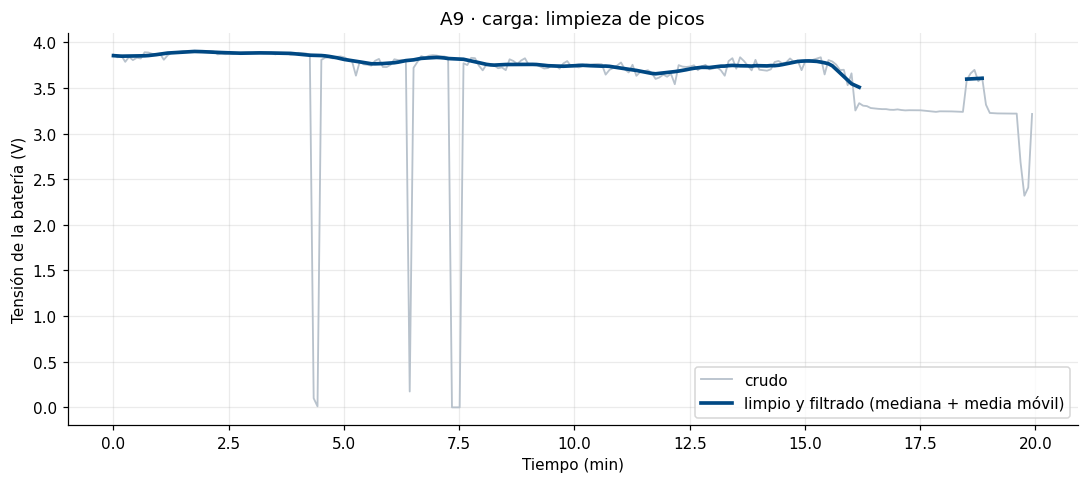

,σ crudo (mV),σ filtrado (mV)
A10,0.930,0.081
A2,1.054,0.283
A3,1.461,0.109
A8,0.996,0.070
B1,0.941,0.069
B19,34.924,9.599
B22,1.220,0.103
B23,1.137,0.059
B24,0.829,0.061
B3,6.410,3.508


In [6]:
# A9: lecturas crudas con picos a 0 V frente a la señal limpia y filtrada.
g, gl = d[d.prueba == "A9"], dl[dl.prueba == "A9"]
fig, ax = plt.subplots()
ax.plot(g.t / 60, g.V, color="#b8c2cc", lw=1.2, label="crudo")
tf, vf = con_huecos(gl.t, gl.V_f)
ax.plot(tf / 60, vf, color=AZUL, lw=2.4, label="limpio y filtrado (mediana + media móvil)")
ax.set(xlabel="Tiempo (min)", ylabel="Tensión de la batería (V)", title="A9 · carga: limpieza de picos")
ax.legend(); guardar(fig, "r1_limpieza.png")
# Variación entre lecturas seguidas de la salida, antes y después del filtro.
ruido = pd.DataFrame({p: {"σ crudo (mV)": 1000 * np.std(np.diff(g.Vs)), "σ filtrado (mV)": 1000 * np.std(np.diff(g.Vs_f))}
                      for p, g in dl.groupby("prueba") if len(g) > 200}).T
display(ruido.round(3))
RES["limpieza"] = {"filas": int(d.shape[0]), "quitadas": int(quitadas.sum()),
                   "ruido_crudo": round(ruido.iloc[:, 0].median(), 2), "ruido_filtrado": round(ruido.iloc[:, 1].median(), 2)}
RES["serie_crudo"] = g[["t", "V"]].assign(t=g.t / 60).round(3).values.tolist()
RES["serie_filtrado"] = gl[["t", "V_f"]].assign(t=gl.t / 60).round(3).values.tolist()

## Requerimiento 2 · Análisis de datos y eficiencia

### 2.1 Eficiencia del convertidor MT3608
η = P<sub>salida</sub> / P<sub>entrada</sub>. Solo tiene sentido cuando la entrada es la batería.
La descarga de referencia es C8: la más larga, de 3.90 V hasta el corte.

In [7]:
bat = dl[dl.fuente == "bateria"]
ef = bat.groupby("prueba").apply(lambda g: pd.Series({
    "P_ent (mW)": g.P.mean(), "P_sal (mW)": g.Ps.mean(), "pérdida (mW)": (g.P - g.Ps).mean(),
    "E_ent (mWh)": g.E.iloc[-1] - g.E.iloc[0], "E_sal (mWh)": g.Es.iloc[-1] - g.Es.iloc[0],
    "η (%)": eficiencia(g.Es.iloc[-1] - g.Es.iloc[0], g.E.iloc[-1] - g.E.iloc[0]),
    "R carga (Ω)": g.R_carga.median()}), include_groups=False)
ef = ef[bat.groupby("prueba").size() > 100]  # fuera las pruebas casi vacías (A7, B20, C2)
display(ef.round(1))
# C8: la eficiencia según la tensión de la batería.
g8 = dl[dl.prueba == "C8"].copy()
g8["eta"] = eficiencia(g8.Ps, g8.P)
tramos = g8.groupby(pd.cut(g8.V, [2.2, 2.6, 3.0, 3.2, 3.4, 3.5, 3.6, 3.7, 3.9]), observed=True).eta.mean()
display(tramos.round(1).to_frame("η (%)"))
RES["eficiencia"] = {k: round(v, 1) for k, v in ef["η (%)"].items()}
RES["perdida"] = {k: round(v, 1) for k, v in ef["pérdida (mW)"].items()}
RES["flujo"] = {k: [round(r["E_ent (mWh)"]), round(r["E_sal (mWh)"])] for k, r in ef.iterrows()}
RES["eta_vs_v"] = [[round(iv.mid, 2), round(v, 1)] for iv, v in tramos.items()]

,P_ent (mW),P_sal (mW),pérdida (mW),E_ent (mWh),E_sal (mWh),η (%),R carga (Ω)
prueba,,,,,,,
A8,813.6,686.1,127.6,3722.5,3138.9,84.3,35.6
B1,156.9,131.3,25.6,445.3,372.7,83.7,189.8
B22,170.1,131.2,38.9,347.1,267.7,77.1,189.8
B24,157.5,131.7,25.8,330.0,275.9,83.6,190.1
B4,157.7,131.2,26.5,453.9,377.7,83.2,189.7
B5,138.0,118.9,19.1,96.5,83.1,86.1,210.1
C4,544.7,472.0,72.7,3331.9,2889.7,86.7,50.2
C6,547.5,472.6,74.9,3765.2,3250.1,86.3,50.9
C8,379.6,327.4,52.2,3957.9,3413.3,86.2,74.6


,η (%)
V,
"(2.2, 2.6]",84.6
"(2.6, 3.0]",85.6
"(3.0, 3.2]",86.3
"(3.2, 3.4]",86.7
"(3.4, 3.5]",85.7
"(3.5, 3.6]",86.0
"(3.6, 3.7]",86.5
"(3.7, 3.9]",86.9


### 2.2 Error porcentual: teórico contra real
| Comparación | Teórico | Real |
|---|---|---|
| Potencia | P = V · I (Python) | potencia que guardó el ESP32 |
| Energía | trapecios (Python) | rectángulos del ESP32 |
| Salida del MT3608 | consigna de 5.00 V | tensión medida en `0x44` (solo con batería: con panel se apaga al irse el sol) |
| Corriente de la batería (C8) | potencia constante: I = P<sub>sal</sub> / (η · V) | corriente medida |
| Eficiencia | 97 % (máximo de la hoja de datos) | η medida |
| Autonomía (descargas completas) | t = E<sub>C8</sub> / P<sub>entrada</sub> | duración medida hasta el corte |

In [8]:
eta0 = g8.eta.median() / 100
g8["I_teo"] = g8.Ps / (eta0 * g8.V)  # el elevador pide más corriente cuando baja la tensión
E_bat = g8.E.iloc[-1] / 1000  # Wh que entregó la batería en C8
# Descargas completas: las que llegaron por debajo de 3.0 V.
completas = [p for p in ef.index if bat[bat.prueba == p].V.iloc[-1] < 3.0]
auto = ef.loc[completas, ["P_ent (mW)"]].set_axis(["P"], axis=1)
auto["t_calc"] = E_bat * 1000 / auto.P
auto["t_med"] = bat.groupby("prueba").h.agg(lambda h: h.max() - h.min())[completas]
val = auto.drop(index="C8")  # C8 da la energía: se valida con las otras
filas = [
    ["Potencia P = V·I", "todas", np.nanmean(error_pct(dl.P, dl.P_esp))],
    ["Energía (trapecio vs ESP32)", "lotes B y C", fin["dif_E_%"][~fin.index.str.startswith("A")].mean()],
    ["Energía (trapecio vs ESP32)", "lote A", fin["dif_E_%"][fin.index.str.startswith("A")].mean()],
    ["Salida 5.00 V", "batería", error_pct(5.0, bat[bat.prueba.isin(ef.index)].Vs).mean()],
    ["Corriente potencia constante", "C8", error_pct(g8.I_teo, g8.I).mean()],
    ["Eficiencia hoja de datos 97 %", "batería", error_pct(97, ef["η (%)"]).mean()],
    ["Autonomía E / P", "descargas completas", error_pct(val.t_calc, val.t_med).mean()],
]
errores = pd.DataFrame(filas, columns=["Comparación", "Pruebas", "Error medio (%)"])
display(errores.round(3))
RES["errores"] = errores.round(3).values.tolist()
RES["eta0"] = round(eta0 * 100, 1)

,Comparación,Pruebas,Error medio (%)
0,Potencia P = V·I,todas,0.000
1,Energía (trapecio vs ESP32),lotes B y C,0.533
2,Energía (trapecio vs ESP32),lote A,13.973
3,Salida 5.00 V,batería,0.759
4,Corriente potencia constante,C8,0.692
5,Eficiencia hoja de datos 97 %,batería,13.244
6,Autonomía E / P,descargas completas,8.648


### 2.3 Modelo de descarga y autonomía
Regresión polinómica de grado 4 de la tensión de la batería contra el tiempo (C8, de 3.90 V hasta el corte).
La autonomía se estima con **t = E<sub>batería</sub> / P<sub>entrada</sub>**, con la energía medida en C8,
y se compara con lo que duraron de verdad las otras descargas completas (A8, C4 y C6).

V(t) = -0.0012·t^4 +0.0212·t^3 -0.1225·t^2 +0.1822·t^1 +3.6629·t^0
R² = 0.9397 · raíz del error cuadrático medio (RMSE) = 57.0 mV


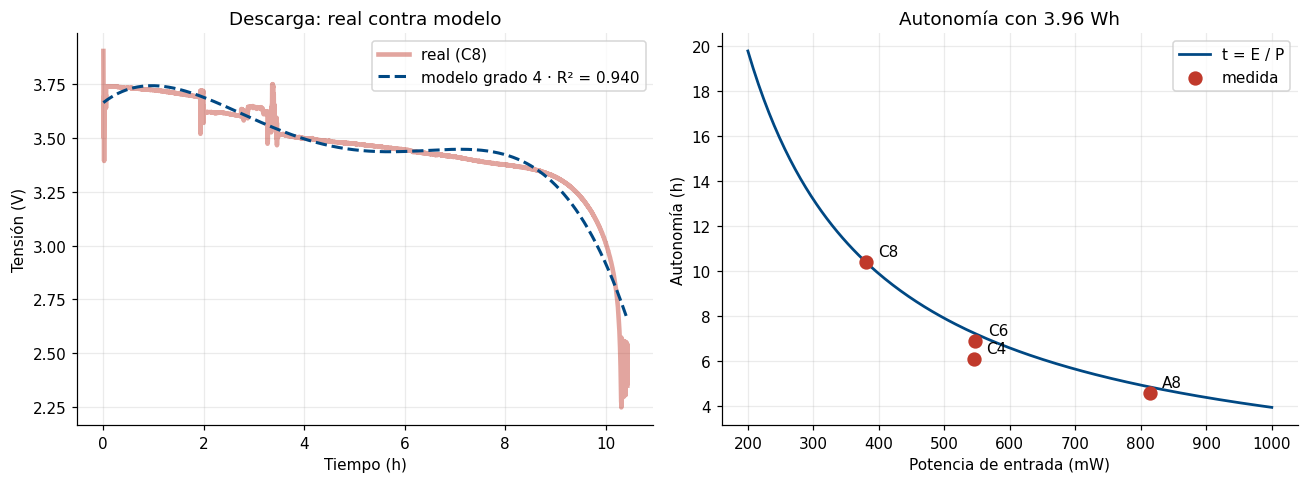

,P,t_calc,t_med
prueba,,,
A8,813.63,4.86,4.58
C4,544.73,7.27,6.12
C6,547.47,7.23,6.92
C8,379.63,10.43,10.42


Pendiente de la meseta (mV/h): {'A8': -75.1, 'B1': -9.9, 'B22': -10.0, 'B24': -8.6, 'B4': -15.9, 'B5': -10.2, 'C4': -60.7, 'C6': -34.1, 'C8': -48.6}


In [9]:
coef = np.polyfit(g8.h, g8.V, 4)
g8["V_mod"] = np.polyval(coef, g8.h)
r2 = 1 - ((g8.V - g8.V_mod) ** 2).sum() / ((g8.V - g8.V.mean()) ** 2).sum()
rmse = np.sqrt(((g8.V - g8.V_mod) ** 2).mean())
print("V(t) =", " ".join(f"{c:+.4f}·t^{4 - k}" for k, c in enumerate(coef)))
print(f"R² = {r2:.4f} · raíz del error cuadrático medio (RMSE) = {1000 * rmse:.1f} mV")
P = np.linspace(200, 1000, 200)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(g8.h, g8.V, color=ROJO, lw=3, alpha=.45, label="real (C8)")
ax[0].plot(g8.h, g8.V_mod, "--", color=AZUL, lw=2, label=f"modelo grado 4 · R² = {r2:.3f}")
ax[0].set(xlabel="Tiempo (h)", ylabel="Tensión (V)", title="Descarga: real contra modelo"); ax[0].legend()
ax[1].plot(P, E_bat * 1000 / P, color=AZUL, label="t = E / P")
ax[1].scatter(auto.P, auto.t_med, color=ROJO, s=70, zorder=4, label="medida")
for p, r in auto.iterrows():
    ax[1].annotate(p, (r.P, r.t_med), xytext=(8, 4), textcoords="offset points")
ax[1].set(xlabel="Potencia de entrada (mW)", ylabel="Autonomía (h)", title=f"Autonomía con {E_bat:.2f} Wh"); ax[1].legend()
guardar(fig, "r2_descarga_autonomia.png")
display(auto.round(2))
pend = bat[bat.prueba.isin(ef.index) & (bat.V > 3.3)].groupby("prueba").apply(lambda g: 1000 * np.polyfit(g.h, g.V, 1)[0], include_groups=False)
print("Pendiente de la meseta (mV/h):", pend.round(1).to_dict())
RES["modelo"] = {"coef": coef.round(5).tolist(), "r2": round(r2, 4), "rmse_mV": round(1000 * rmse, 1), "E_Wh": round(E_bat, 3),
                 "t_corte": round(g8.h.max(), 2), "P8_mW": round(g8.P.mean(), 1), "n": int(len(g8))}
RES["autonomia"] = {p: [round(r.P, 1), round(r.t_calc, 2), round(r.t_med, 2)] for p, r in auto.iterrows()}
RES["pendiente"] = {k: round(v, 1) for k, v in pend.items()}
paso = max(1, len(g8) // 140)
cols = ["h", "V", "V_mod", "I", "I_teo"]
RES["serie_descarga"] = pd.concat([g8[cols].iloc[::paso], g8[cols].iloc[[-1]]]).drop_duplicates().round(3).values.tolist()  # incluye el corte final
RES["V_corte"] = round(g8.V.iloc[-1], 2)

### 2.4 Detectar pérdidas y caídas de tensión
- **Pérdida en el elevador**: E<sub>entrada</sub> − E<sub>salida</sub> en cada descarga.
- **Resistencia en serie**: en A9 (carga) la tensión sube y baja con la corriente.
  Regresión V = V<sub>0</sub> + R · I: la pendiente suma la resistencia interna de las celdas, cables, contactos y portapilas.
- **Saltos bruscos**: `np.diff` sobre la tensión; se marca todo salto mayor que 8 veces la variación típica, con un mínimo de 50 mV.

prueba,A1,A2,A3,A6,A7,A8,A9,A10,B1,B3,...,B23,B24,C1,C2,C3,C4,C5,C6,C7,C8
saltos,10.0,17.0,74.0,0.0,1.0,0.0,2.0,9.0,0.0,5.0,...,14.0,0.0,52.0,1.0,16.0,115.0,233.0,4.0,126.0,124.0
mayor_mV,625.0,1167.0,1326.0,0.0,79.0,0.0,327.0,93.0,0.0,160.0,...,909.0,0.0,625.0,1036.0,147.0,412.0,906.0,192.0,1165.0,326.0


,E_ent (mWh),E_sal (mWh),perdida,perdida_%
prueba,,,,
A8,3722.5,3138.9,583.6,15.7
B1,445.3,372.7,72.7,16.3
B22,347.1,267.7,79.4,22.9
B24,330.0,275.9,54.1,16.4
B4,453.9,377.7,76.2,16.8
B5,96.5,83.1,13.4,13.9
C4,3331.9,2889.7,442.2,13.3
C6,3765.2,3250.1,515.1,13.7
C8,3957.9,3413.3,544.5,13.8


A9: V = 3.153 V + 1.80 Ω · I   (R² = 0.893, 192 puntos)
Con 0.4 A se pierden 0.72 V y 288 mW en esa resistencia (P = R·I²)


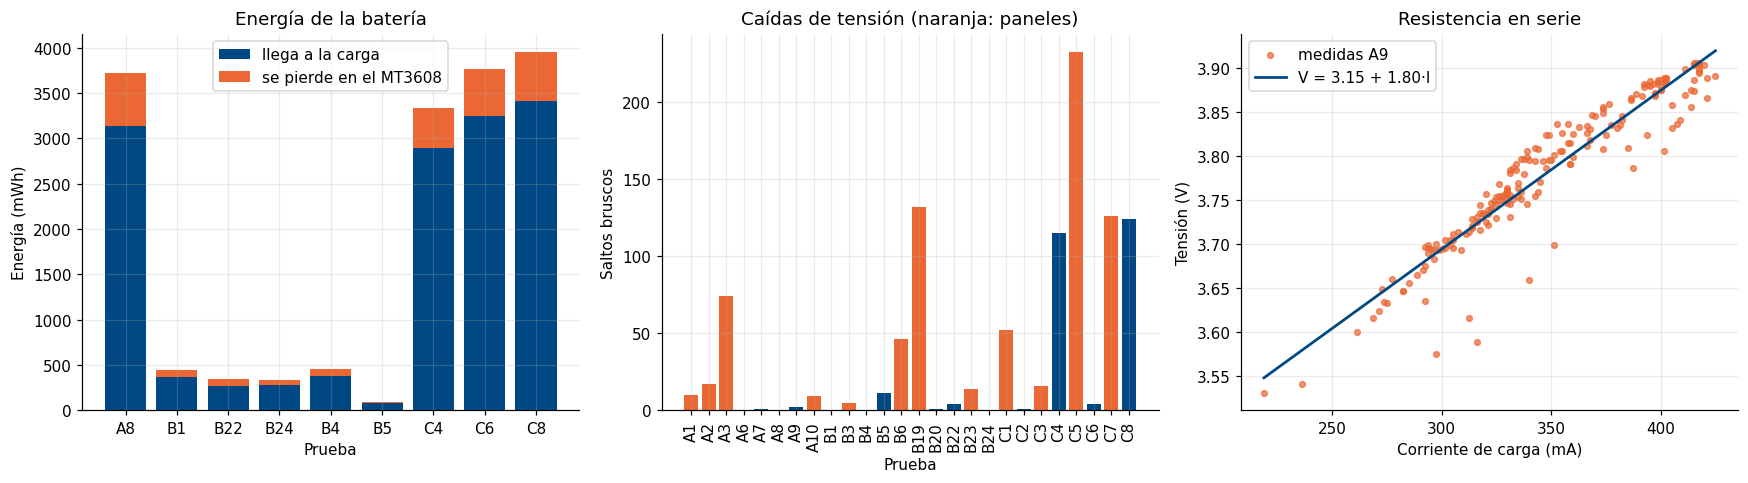

In [10]:
eventos = []
for p, g in dl.groupby("prueba"):
    c = caidas(g.t.values, g.V.values, g.I.values)
    eventos.append(c.assign(prueba=p))
ev = pd.concat(eventos)
resumen_ev = ev.groupby("prueba").agg(saltos=("dV", "size"), mayor_mV=("dV", lambda x: 1000 * x.abs().max()))
resumen_ev = resumen_ev.reindex(dl.prueba.unique(), fill_value=0)
display(resumen_ev.T.round(0))
perd = ef[["E_ent (mWh)", "E_sal (mWh)"]].assign(perdida=lambda x: x.iloc[:, 0] - x.iloc[:, 1])
perd["perdida_%"] = 100 * perd.perdida / perd["E_ent (mWh)"]
display(perd.round(1))
g9 = d[(d.prueba == "A9") & (d.V > 3) & (d.I > 50)]
R_serie, V0 = np.polyfit(g9.I / 1000, g9.V, 1)
r9 = np.corrcoef(g9.I, g9.V)[0, 1] ** 2
print(f"A9: V = {V0:.3f} V + {R_serie:.2f} Ω · I   (R² = {r9:.3f}, {len(g9)} puntos)")
print(f"Con 0.4 A se pierden {R_serie * 0.4:.2f} V y {R_serie * 0.4 ** 2 * 1000:.0f} mW en esa resistencia (P = R·I²)")
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[2].scatter(g9.I, g9.V, s=14, color=NAR, alpha=.7, label="medidas A9")
xi = np.linspace(g9.I.min(), g9.I.max(), 10)
ax[2].plot(xi, V0 + R_serie * xi / 1000, color=AZUL, label=f"V = {V0:.2f} + {R_serie:.2f}·I")
ax[2].set(xlabel="Corriente de carga (mA)", ylabel="Tensión (V)", title="Resistencia en serie"); ax[2].legend()
x = perd.index.astype(str)
ax[0].bar(x, perd["E_sal (mWh)"], color=AZUL, label="llega a la carga")
ax[0].bar(x, perd.perdida, bottom=perd["E_sal (mWh)"], color=NAR, label="se pierde en el MT3608")
ax[0].set(xlabel="Prueba", ylabel="Energía (mWh)", title="Energía de la batería"); ax[0].legend()
ax[1].bar(resumen_ev.index.astype(str), resumen_ev.saltos, color=[NAR if f == "paneles" else AZUL for f in pruebas.fuente[resumen_ev.index]])
ax[1].set(xlabel="Prueba", ylabel="Saltos bruscos", title="Caídas de tensión (naranja: paneles)"); ax[1].tick_params(axis="x", rotation=90)
guardar(fig, "r2_perdidas.png")
RES["perdidas"] = {"saltos": int(len(ev)), "por_prueba": {p: int(v) for p, v in resumen_ev.saltos.items()},
                   "mayor_mV": round(float(resumen_ev.mayor_mV.max())), "pct": {p: round(v, 1) for p, v in perd["perdida_%"].items()},
                   "R_serie": round(R_serie, 2), "V0": round(V0, 3), "r2": round(r9, 3), "n": int(len(g9)),
                   "puntos": g9[["I", "V"]].round(3).values.tolist()}

## Requerimiento 3 · Visualización y validación de resultados

### 3.1 Curvas superpuestas: teórico contra real

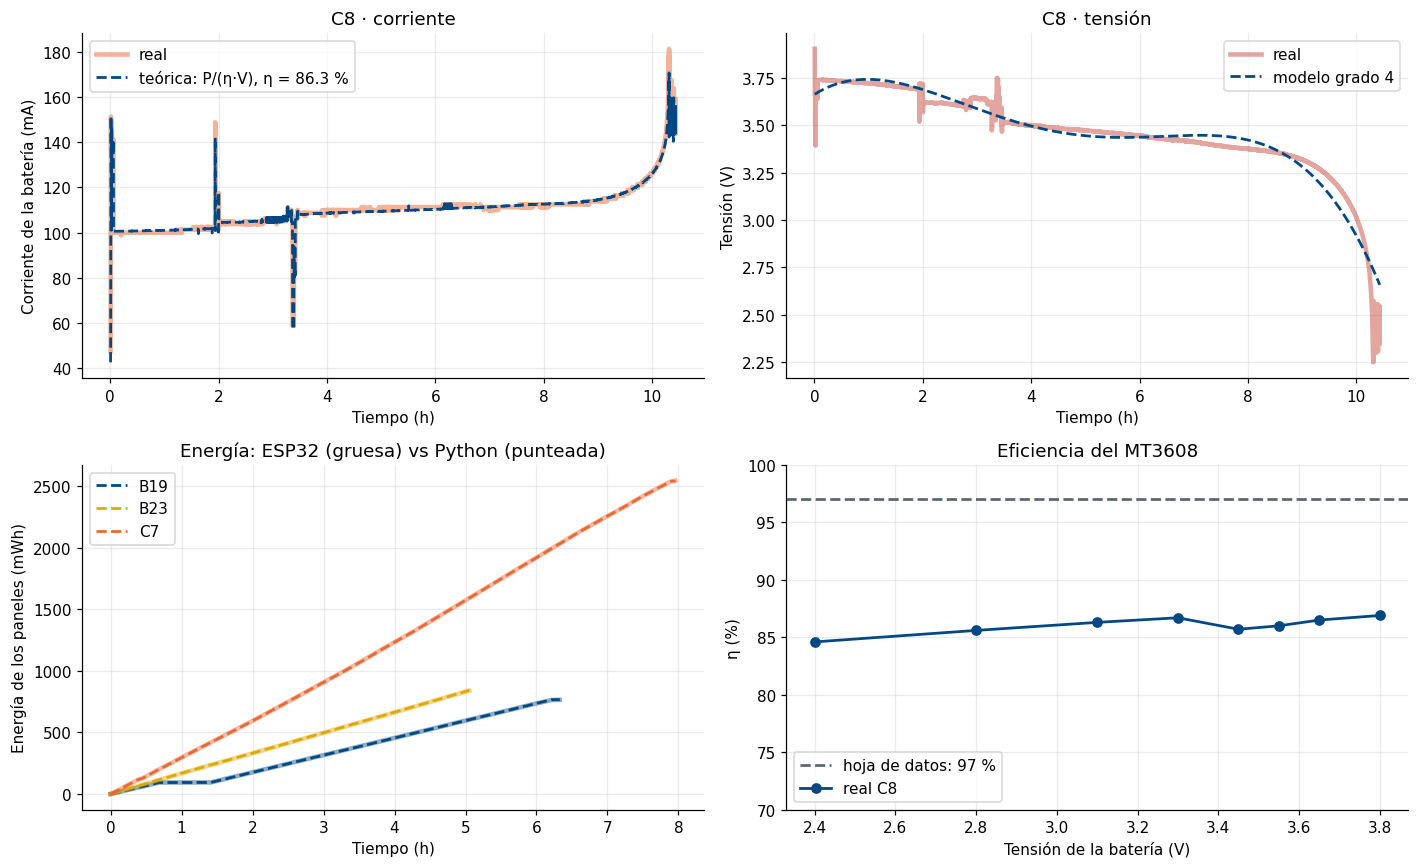

In [11]:
fig, ax = plt.subplots(2, 2, figsize=(13, 8))
ax[0, 0].plot(g8.h, g8.I, color=NAR, lw=3, alpha=.5, label="real")
ax[0, 0].plot(g8.h, g8.I_teo, "--", color=AZUL, label=f"teórica: P/(η·V), η = {eta0 * 100:.1f} %")
ax[0, 0].set(xlabel="Tiempo (h)", ylabel="Corriente de la batería (mA)", title="C8 · corriente"); ax[0, 0].legend()
ax[0, 1].plot(g8.h, g8.V, color=ROJO, lw=3, alpha=.45, label="real")
ax[0, 1].plot(g8.h, g8.V_mod, "--", color=AZUL, label="modelo grado 4")
ax[0, 1].set(xlabel="Tiempo (h)", ylabel="Tensión (V)", title="C8 · tensión"); ax[0, 1].legend()
for p, c in [("B19", AZUL), ("B23", AMAR), ("C7", NAR)]:
    g = d[d.prueba == p]
    ax[1, 0].plot(g.h - g.h.iloc[0], g.E_esp, color=c, lw=3, alpha=.45)
    ax[1, 0].plot(g.h - g.h.iloc[0], g.E, "--", color=c, label=p)
ax[1, 0].set(xlabel="Tiempo (h)", ylabel="Energía de los paneles (mWh)", title="Energía: ESP32 (gruesa) vs Python (punteada)"); ax[1, 0].legend()
v, e = zip(*RES["eta_vs_v"])
ax[1, 1].axhline(97, color=GRIS, ls="--", label="hoja de datos: 97 %")
ax[1, 1].plot(v, e, "o-", color=AZUL, label="real C8")
ax[1, 1].set(xlabel="Tensión de la batería (V)", ylabel="η (%)", ylim=(70, 100), title="Eficiencia del MT3608"); ax[1, 1].legend()
guardar(fig, "r3_teorico_vs_real.png")

### 3.2 Tablas resumen para el informe

In [12]:
resumen = dl.groupby("prueba", sort=False).agg(fuente=("fuente", "first"), horas=("h", "max"), muestras=("n", "size"),
    V_media=("V", "mean"), V_min=("V", "min"), V_max=("V", "max"), I_media=("I", "mean"),
    P_media=("P", "mean"), E_mWh=("E", "last"), Vs_media=("Vs", "mean"), Is_media=("Is", "mean"), Ps_media=("Ps", "mean"))
por_fuente = dl.groupby("fuente")[["V", "I", "P", "Vs", "Is", "Ps"]].describe().T
display(resumen.round(3)); display(por_fuente.round(3))
resumen.round(4).to_csv(TAB / "resumen_pruebas.csv", encoding="utf-8-sig")
with pd.ExcelWriter(TAB / "tablas_corte3.xlsx") as x:
    for nombre, t in {"Resumen": resumen, "Por fuente": por_fuente, "Eficiencia": ef, "Errores": errores.set_index("Comparación"),
                      "Autonomía": auto, "Eventos": resumen_ev}.items():
        t.round(4).to_excel(x, sheet_name=nombre)
print("Tablas guardadas en tablas/")
RES["resumen"] = resumen.reset_index()[["prueba", "fuente", "horas", "V_media", "P_media", "E_mWh"]].round(3).values.tolist()

,fuente,horas,muestras,V_media,V_min,V_max,I_media,P_media,E_mWh,Vs_media,Is_media,Ps_media
prueba,,,,,,,,,,,,
A1,paneles,21.740,176,4.519,3.439,4.809,130.321,590.460,28.792,4.957,22.500,111.534
A2,paneles,0.813,807,4.506,3.436,5.155,117.281,507.585,149.312,4.972,22.502,111.872
A3,paneles,0.356,935,4.601,3.464,5.221,103.845,479.884,173.565,4.970,22.500,111.817
A6,bateria,0.141,4,3.554,3.535,3.568,238.150,846.322,-15.897,4.934,143.750,709.188
A7,bateria,8.625,17,3.591,3.541,3.640,233.188,837.065,17.780,4.933,143.476,707.775
A8,bateria,4.575,3295,3.441,2.810,3.640,237.154,813.634,3722.512,4.942,138.831,686.066
A9,carga,0.314,193,3.779,3.333,3.905,346.462,1313.273,350.354,4.940,143.067,706.785
A10,paneles,2.681,1935,4.315,4.223,4.523,206.542,890.846,2388.368,4.951,142.315,704.647
B1,bateria,2.842,2044,3.867,3.851,3.893,40.567,156.865,445.451,4.991,26.301,131.262


fuente      bateria     carga    paneles
V  count  27916.000   193.000  30145.000
   mean       3.563     3.779      4.201
   std        0.251     0.089      0.735
   min        2.039     3.333      2.007
   25%        3.441     3.725      3.746
   50%        3.551     3.786      4.259
   75%        3.726     3.849      4.810
   max        3.945     3.905      5.666
I  count  27916.000   193.000  30145.000
   mean     122.891   346.462     70.536
   std       63.585    49.884     46.952
   min        2.500     2.500      2.500
   25%       46.300   317.500     32.500
   50%      113.800   340.000     68.800
   75%      163.800   387.500     88.800
   max      306.300   425.000    228.800
P  count  27916.000   193.000  30145.000
   mean     427.159  1313.273    293.223
   std      209.141   212.322    196.304
   min        5.098     8.332      5.018
   25%      170.199  1188.720    158.994
   50%      384.096  1289.134    288.688
   75%      572.480  1493.436    348.945
   max      967.150  1653.675    966.222
Vs count  27916.000   193.000  30145.000
   mean       4.962     4.940      4.788
   std        0.035     0.003      0.570
   min        2.041     4.931      2.050
   25%        4.948     4.939      4.969
   50%        4.961     4.941      4.988
   75%        4.989     4.943      5.001
   max        5.020     4.945      5.046
Is count  27916.000   193.000  30145.000
   mean      73.715   143.067     46.305
   std       36.274     2.729     30.534
   min        2.500   140.000      2.500
   25%       26.300   141.300     23.800
   50%       66.300   141.300     43.800
   75%      100.000   146.300     58.800
   max      163.800   152.500    153.800
Ps count  27916.000   193.000  30145.000
   mean     365.275   706.785    227.074
   std      179.196    13.204    153.539
   min        5.102   691.740      5.125
   25%      131.500   698.163    112.703
   50%      328.119   698.446    219.000
   75%      496.000   721.990    293.000
   max      805.077   751.978    760.541

Tablas guardadas en tablas/


### 3.3 Estabilidad de la tensión
Desviación estándar (σ) con `np.std` y coeficiente de variación CV = σ / media.
La salida del MT3608 debe ser estable; la batería baja poco a poco y el panel cambia con el sol.

,fuente,Vs media (V),σ Vs (mV),CV Vs (%),σ V entrada (mV)
prueba,,,,,
A1,paneles,4.957,3.591,0.072,123.738
A2,paneles,4.972,5.777,0.116,732.317
A3,paneles,4.970,2.240,0.045,521.646
A6,bateria,4.934,1.500,0.030,12.787
A7,bateria,4.933,1.731,0.035,39.456
A8,bateria,4.942,2.225,0.045,163.532
A9,carga,4.940,2.720,0.055,88.324
A10,paneles,4.951,2.693,0.054,50.573
B1,bateria,4.991,0.890,0.018,8.275


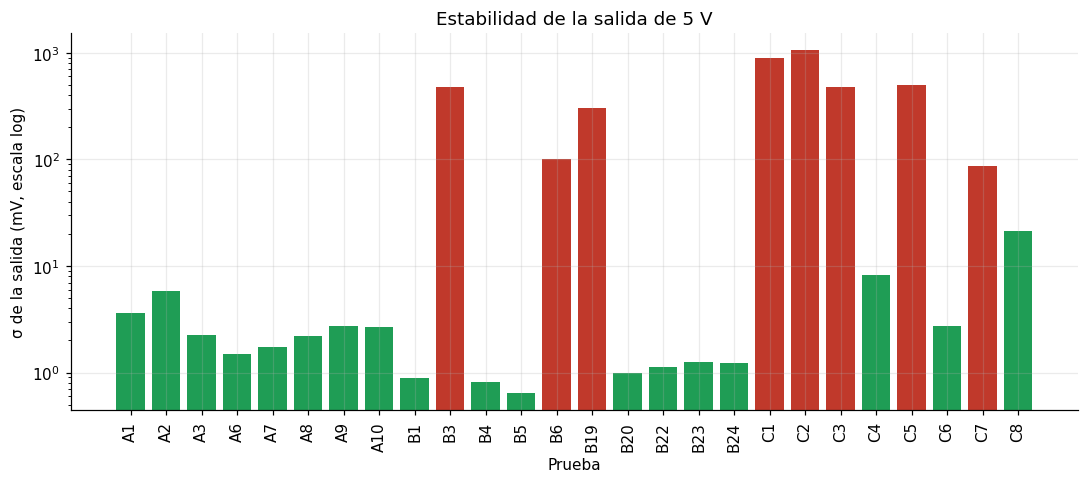

In [13]:
est = dl.groupby("prueba", sort=False).apply(lambda g: pd.Series({
    "fuente": g.fuente.iat[0], "Vs media (V)": np.mean(g.Vs), "σ Vs (mV)": 1000 * np.std(g.Vs),
    "CV Vs (%)": 100 * np.std(g.Vs) / np.mean(g.Vs), "σ V entrada (mV)": 1000 * np.std(g.V)}), include_groups=False)
display(est.round(3))
fig, ax = plt.subplots()
col = [VERDE if s < 25 else ROJO for s in est["σ Vs (mV)"]]
ax.bar(est.index.astype(str), est["σ Vs (mV)"], color=col)
ax.set(yscale="log", xlabel="Prueba", ylabel="σ de la salida (mV, escala log)", title="Estabilidad de la salida de 5 V"); ax.tick_params(axis="x", rotation=90)
guardar(fig, "r3_estabilidad.png")
RES["estabilidad"] = {p: [r.fuente, round(r["Vs media (V)"], 3), round(r["σ Vs (mV)"], 2)] for p, r in est.iterrows()}

### 3.4 Datos para la presentación
Se guardan los números que usan las diapositivas, para que salgan del mismo cálculo.

In [14]:
(RAIZ / "resultados.json").write_text(json.dumps(RES, ensure_ascii=False, default=float), encoding="utf-8")
print("resultados.json listo ·", len(RES), "bloques")

resultados.json listo · 21 bloques
